# FoodVision AI — Custom CNN (270 Food Classes)

**One notebook for the complete Custom CNN workflow.** Run cells from top to bottom.
Uses your existing cleaned train/validation CSV files. **No imports from `ml/src` scripts.**

The test split is deliberately untouched. All model files are saved under `ml/experiments/custom_cnn/` (ignored by Git).

**Important:** Train with Jupyter started from the `tf_gpu` Anaconda Prompt, where your RTX 3050 GPU is detected.

## 1. Setup

In [5]:
from pathlib import Path
import csv
import json
import io
import random

import numpy as np
import tensorflow as tf
from PIL import Image

# Change this only if your images are stored elsewhere.
DATASET_ROOT = Path(r"C:\deep_learning_projects\archive\images")
BATCH_SIZE = 32
SEED = 42
IMAGE_SIZE = (224, 224)

# Works when the notebook is opened from the project root or ml/notebooks/.
current = Path.cwd()
PROJECT_ROOT = next(
    (p for p in (current, *current.parents)
     if (p / "ml" / "data" / "splits" / "train.csv").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate ml/data/splits/train.csv. Run the notebook inside the foodvision-ai project.")
if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_ROOT}")

SPLITS_DIR = PROJECT_ROOT / "ml" / "data" / "splits"
with (SPLITS_DIR / "class_to_index.json").open("r", encoding="utf-8") as f:
    CLASS_TO_INDEX = json.load(f)
NUM_CLASSES = len(CLASS_TO_INDEX)

tf.keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # GPU may already have been initialized in this kernel.

print("Project:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)
print("GPU:", gpus)
print("Number of food classes:", NUM_CLASSES)

Project: C:\deep_learning_projects\foodvision-ai
TensorFlow: 2.10.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Number of food classes: 270


## 2. Read images from the existing train/validation CSVs

Images are loaded only when needed; this avoids loading all ~225k images into RAM. No new CSV files are created.

In [6]:
def read_split(filename):
    paths, labels = [], []
    with (SPLITS_DIR / filename).open("r", encoding="utf-8", newline="") as f:
        for row in csv.DictReader(f):
            relative = Path(*row["relative_path"].replace("\\", "/").split("/"))
            paths.append(str(DATASET_ROOT / relative))
            labels.append(int(row["class_index"]))
    return paths, labels


def decode_webp(encoded):
    # WebP images are decoded with Pillow; JPEG/PNG/BMP use TensorFlow.
    if hasattr(encoded, "item"):
        encoded = encoded.item()
    with Image.open(io.BytesIO(encoded)) as img:
        return np.asarray(img.convert("RGB"), dtype=np.uint8)


def read_image(path, label):
    raw = tf.io.read_file(path)
    is_webp = tf.strings.regex_full_match(tf.strings.lower(path), r".*\.webp")
    image = tf.cond(
        is_webp,
        lambda: tf.numpy_function(decode_webp, [raw], tf.uint8),
        lambda: tf.io.decode_image(raw, channels=3, expand_animations=False),
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE, antialias=True)
    # Keep raw 0–255 pixels. CNN rescales inside the model;
    # EfficientNetB0 includes its own preprocessing.
    image = tf.clip_by_value(image, 0.0, 255.0)
    return image, tf.cast(label, tf.int32)


def make_dataset(filename, training=False):
    paths, labels = read_split(filename)
    if training:
        paired = list(zip(paths, labels))
        random.Random(SEED).shuffle(paired)
        paths, labels = zip(*paired)

    ds = tf.data.Dataset.from_tensor_slices((list(paths), list(labels)))
    if training:
        ds = ds.shuffle(min(2048, len(paths)), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(read_image, num_parallel_calls=2)
    ds = ds.batch(BATCH_SIZE).prefetch(1)
    return ds, len(paths)


train_ds, train_count = make_dataset("train.csv", training=True)
val_ds, val_count = make_dataset("val.csv", training=False)
print(f"Training: {train_count:,} images | Validation: {val_count:,} images")
print("One batch:", next(iter(train_ds))[0].shape)

Training: 157,800 images | Validation: 33,813 images
One batch: (32, 224, 224, 3)


## 3. Build the Custom CNN

This is your existing architecture: Rescaling → Conv/BN/ReLU/MaxPool → GlobalAveragePooling → Dense → Softmax. Adam learning rate is **0.001**.

In [7]:
from tensorflow.keras import layers, Model

def build_custom_cnn():
    inputs = layers.Input(shape=(224, 224, 3), name="input_image")
    x = layers.Rescaling(1.0 / 255.0)(inputs)

    x = layers.Conv2D(32, 3, strides=2, padding="same", use_bias=False)(x)
    x = layers.LayerNormalization(axis=-1)(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

    for filters in (64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)

   
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    predictions = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = Model(inputs, predictions, name="foodvision_custom_cnn")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(
                k=5, name="top5_accuracy"
            ),
        ],
    )
    return model

model = build_custom_cnn()
model.summary()

Model: "foodvision_custom_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_image (InputLayer)    [(None, 224, 224, 3)]     0         
                                                                 
 rescaling_1 (Rescaling)     (None, 224, 224, 3)       0         
                                                                 
 conv2d_4 (Conv2D)           (None, 112, 112, 32)      864       
                                                                 
 layer_normalization_1 (Laye  (None, 112, 112, 32)     64        
 rNormalization)                                                 
                                                                 
 activation_4 (Activation)   (None, 112, 112, 32)      0         
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 56, 56, 32)       0         
 2D)                                         

## 4. Train and save the best checkpoint

This trains on **all 157,800** training images, not the small pilots. Start with `EPOCHS = 5`, monitor validation loss, and adjust only if needed. On a laptop GPU, full-data training may take a while.

In [8]:
# Edit this one number if needed.
MODEL_NAME = 'custom_cnn'
EPOCHS = 10

OUTPUT_DIR = PROJECT_ROOT / "ml" / "experiments" / "custom_cnn_v2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT = OUTPUT_DIR / "best_model.h5"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(CHECKPOINT), monitor="val_loss", save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.CSVLogger(str(OUTPUT_DIR / "training_log.csv")),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)
print("Best checkpoint:", CHECKPOINT)

Epoch 1/10
4932/4932 [==============================] - ETA: 0s - loss: 4.2833 - accuracy: 0.0985 - top5_accuracy: 0.2762
Epoch 1: val_loss improved from inf to 4.28617, saving model to C:\deep_learning_projects\foodvision-ai\ml\experiments\custom_cnn_v2\best_model.h5
4932/4932 [==============================] - 517s 105ms/step - loss: 4.2833 - accuracy: 0.0985 - top5_accuracy: 0.2762 - val_loss: 4.2862 - val_accuracy: 0.1110 - val_top5_accuracy: 0.2909 - lr: 0.0010
Epoch 2/10
4931/4932 [============================>.] - ETA: 0s - loss: 3.5071 - accuracy: 0.1958 - top5_accuracy: 0.4488
Epoch 2: val_loss improved from 4.28617 to 3.53225, saving model to C:\deep_learning_projects\foodvision-ai\ml\experiments\custom_cnn_v2\best_model.h5
4932/4932 [==============================] - 546s 111ms/step - loss: 3.5072 - accuracy: 0.1958 - top5_accuracy: 0.4488 - val_loss: 3.5323 - val_accuracy: 0.1957 - val_top5_accuracy: 0.4378 - lr: 0.0010
Epoch 3/10
4931/4932 [============================>.] 

KeyboardInterrupt: 

## 5. Evaluate on validation data and save metrics

Save the metrics to compare with EfficientNet later. **Do not evaluate on the test split yet.**

8454/8454 - 50s - loss: 5.4595 - accuracy: 0.0135 - top5_accuracy: 0.0512 - 50s/epoch - 6ms/step
Validation metrics: {'loss': 5.459465980529785, 'accuracy': 0.01345636323094368, 'top5_accuracy': 0.05116375535726547}


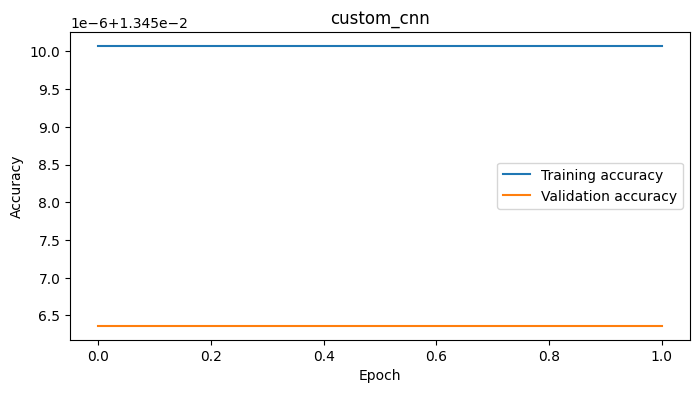

Saved metrics: C:\deep_learning_projects\foodvision-ai\ml\experiments\custom_cnn\metrics.json


In [9]:
# Evaluate the BEST validation checkpoint, not just the last epoch.
best_model = tf.keras.models.load_model(str(CHECKPOINT), compile=False)
best_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy"),
    ],
)
metrics = best_model.evaluate(val_ds, return_dict=True, verbose=2)
print("Validation metrics:", metrics)

report = {
    "model": MODEL_NAME,
    "classes": NUM_CLASSES,
    "train_images": train_count,
    "validation_images": val_count,
    "validation": {k: float(v) for k, v in metrics.items()},
    "checkpoint": str(CHECKPOINT),
}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
(OUTPUT_DIR / "class_to_index.json").write_text(
    json.dumps(CLASS_TO_INDEX, indent=2), encoding="utf-8"
)

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title(MODEL_NAME)
plt.show()
print("Saved metrics:", OUTPUT_DIR / "metrics.json")

**Done:** Custom CNN trained, best checkpoint saved, validation metrics available. Next notebook: `02_efficientnet_b0.ipynb`.

In [10]:

from collections import Counter
import numpy as np

# Load the best saved model
best_model = tf.keras.models.load_model(
    str(CHECKPOINT),
    compile=False,
)

# Predict on 200 validation images
predictions = []

for images, labels in val_ds.take(50):
    outputs = best_model(images, training=False)
    predictions.extend(
        np.argmax(outputs.numpy(), axis=1)
    )

# Convert class indices back into food names
index_to_class = {
    index: name
    for name, index in CLASS_TO_INDEX.items()
}

print("Predictions checked:", len(predictions))
print("Unique predicted classes:", len(set(predictions)))

print("\nMost predicted foods:")
for index, count in Counter(predictions).most_common(5):
    print(index_to_class[index], ":", count)


Predictions checked: 200
Unique predicted classes: 1

Most predicted foods:
pizza : 200
